In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
ZIPS = '/content/drive/MyDrive/speech-denoiser/zips'   # stockage permanent
DATA = '/content/data'                                  # copie locale rapide
os.makedirs(ZIPS, exist_ok=True)
os.makedirs(DATA, exist_ok=True)

Mounted at /content/drive


In [2]:
!pip install -q -U datasets soundfile

from datasets import load_dataset, Audio
ds = load_dataset("JacobLinCool/VoiceBank-DEMAND-16k", cache_dir="/content/hf_cache")

# On lit l'audio nous-mêmes avec soundfile (plus robuste)
ds = ds.cast_column("clean", Audio(decode=False)).cast_column("noisy", Audio(decode=False))
print(ds)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 15.4 MB/s eta 0:00:00


README.md:   0%|          | 0.00/652 [00:00<?, ?B/s]

data/train-00000-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  444MB            

data/train-00000-of-00005.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  416MB            

...

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  132MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11572 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/824 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'clean', 'noisy'],
        num_rows: 11572
    })
    test: Dataset({
        features: ['id', 'clean', 'noisy'],
        num_rows: 824
    })
})


In [3]:
import io, soundfile as sf

def read_audio(a):
    src = io.BytesIO(a["bytes"]) if a.get("bytes") else a["path"]
    x, sr = sf.read(src)
    return x, sr

def load_pair(ex):
    noisy, sr = read_audio(ex["noisy"])
    clean, _  = read_audio(ex["clean"])
    return noisy, clean, sr

Fréquence d'échantillonnage : 16000 Hz | Durée : 2.28 s
Bruitée :


Propre :


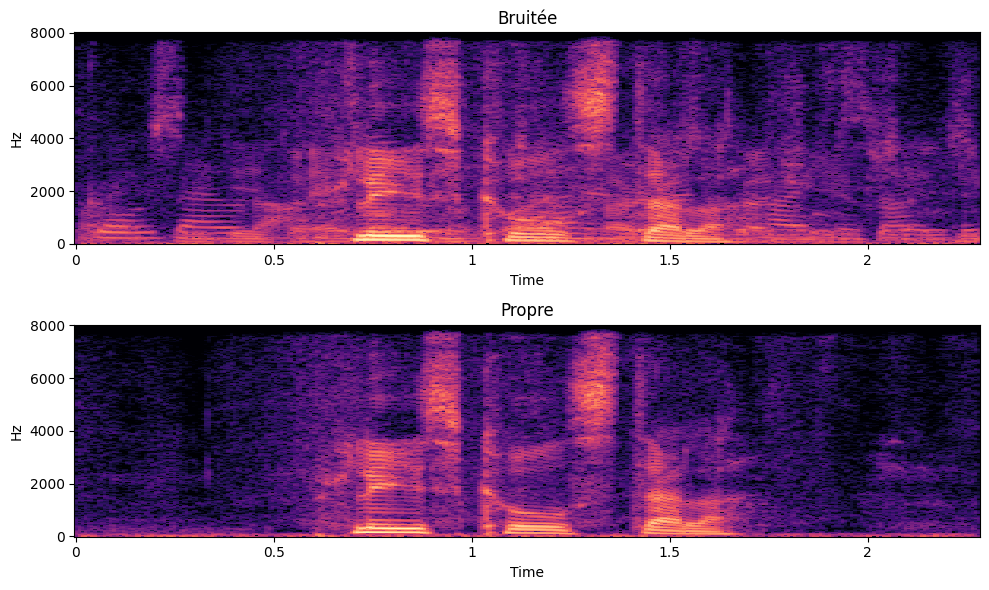

In [4]:
import numpy as np, librosa, librosa.display, matplotlib.pyplot as plt
from IPython.display import Audio as Play, display

i = 0  # change pour écouter d'autres exemples
x_n, x_c, sr = load_pair(ds["train"][i])
print("Fréquence d'échantillonnage :", sr, "Hz | Durée :", round(len(x_c)/sr, 2), "s")

print("Bruitée :"); display(Play(x_n, rate=sr))
print("Propre :");  display(Play(x_c, rate=sr))

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, x, title in zip(axes, [x_n, x_c], ["Bruitée", "Propre"]):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(x, n_fft=512, hop_length=128)), ref=np.max)
    librosa.display.specshow(S, sr=sr, hop_length=128, x_axis='time', y_axis='hz', ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.show()

In [5]:
import numpy as np
from tqdm.auto import tqdm

SR = 16000
def to_int16(x):
    return (np.clip(x, -1, 1) * 32767).astype(np.int16)  # int16 = 2x moins de RAM

def load_split(split):
    N, C = [], []
    for ex in tqdm(ds[split], desc=split):
        n, c, _ = load_pair(ex)
        L = min(len(n), len(c))
        N.append(to_int16(n[:L])); C.append(to_int16(c[:L]))
    return N, C

train_noisy, train_clean = load_split("train")
test_noisy,  test_clean  = load_split("test")
hours = sum(len(x) for x in train_noisy) / SR / 3600
print(f"{len(train_noisy)} clips d'entraînement, {hours:.1f} h d'audio")

train:   0%|          | 0/11572 [00:00<?, ?it/s]

test:   0%|          | 0/824 [00:00<?, ?it/s]

11572 clips d'entraînement, 9.4 h d'audio


In [6]:
import tensorflow as tf

N_FFT = 512   # fenêtre de 32 ms à 16 kHz
HOP   = 128   # pas de 8 ms
win   = tf.signal.hann_window

def stft(x):
    return tf.signal.stft(x, frame_length=N_FFT, frame_step=HOP, fft_length=N_FFT, window_fn=win)

def istft(S):
    return tf.signal.inverse_stft(S, N_FFT, HOP, N_FFT,
        window_fn=tf.signal.inverse_stft_window_fn(HOP, forward_window_fn=win))

def snr_db(clean, est):
    L = min(len(clean), len(est)); clean, est = clean[:L], est[:L]
    return 10 * np.log10(np.sum(clean**2) / (np.sum((clean - est)**2) + 1e-10))

SNR bruité : 12.3 dB  ->  SNR avec masque oracle : 19.9 dB
Bruitée :


Masque oracle :


Propre :


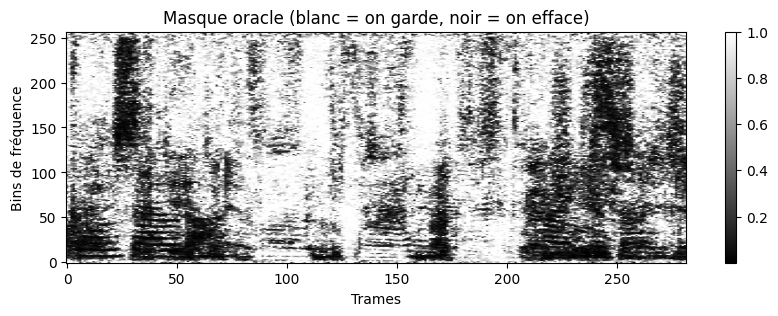

In [7]:
i = 0
n = train_noisy[i].astype(np.float32) / 32767
c = train_clean[i].astype(np.float32) / 32767

Sn, Sc = stft(n), stft(c)
mask = tf.clip_by_value(tf.abs(Sc) / (tf.abs(Sn) + 1e-8), 0.0, 1.0)
enh = istft(tf.cast(mask, tf.complex64) * Sn).numpy()

print(f"SNR bruité : {snr_db(c, n):.1f} dB  ->  SNR avec masque oracle : {snr_db(c, enh):.1f} dB")
print("Bruitée :");        display(Play(n, rate=SR))
print("Masque oracle :");  display(Play(enh, rate=SR))
print("Propre :");         display(Play(c, rate=SR))

plt.figure(figsize=(10, 3))
plt.imshow(mask.numpy().T, origin="lower", aspect="auto", cmap="gray")
plt.title("Masque oracle (blanc = on garde, noir = on efface)")
plt.xlabel("Trames"); plt.ylabel("Bins de fréquence"); plt.colorbar(); plt.show()

In [8]:
SEG = 2 * SR
rng = np.random.default_rng(0)

def gen():
    while True:
        i = rng.integers(len(train_noisy))
        n, c = train_noisy[i], train_clean[i]
        if len(n) < SEG:
            pad = SEG - len(n); n = np.pad(n, (0, pad)); c = np.pad(c, (0, pad))
        s = rng.integers(0, len(n) - SEG + 1)
        yield n[s:s+SEG].astype(np.float32) / 32767, c[s:s+SEG].astype(np.float32) / 32767

def to_features(n, c):
    mag_n = tf.abs(stft(n)); mag_c = tf.abs(stft(c))
    x = tf.math.log(mag_n + 1e-6)          # entrée du réseau : log-magnitude bruitée
    y = tf.stack([mag_n, mag_c], axis=-1)  # pour la loss : magnitudes bruitée + propre
    return x, y

spec = tf.TensorSpec([SEG], tf.float32)
train_ds = (tf.data.Dataset.from_generator(gen, output_signature=(spec, spec))
            .map(to_features, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(32).prefetch(tf.data.AUTOTUNE))

xb, yb = next(iter(train_ds))
print("Entrée :", xb.shape, "| Cible :", yb.shape)

Entrée : (32, 247, 257) | Cible : (32, 247, 257, 2)


In [9]:
val_noisy,   val_clean   = train_noisy[-500:], train_clean[-500:]
train_noisy, train_clean = train_noisy[:-500], train_clean[:-500]

def fixed_crops(N, C):
    out_n, out_c = [], []
    for n, c in zip(N, C):
        n, c = n[:SEG], c[:SEG]
        if len(n) < SEG:
            pad = SEG - len(n); n = np.pad(n, (0, pad)); c = np.pad(c, (0, pad))
        out_n.append(n); out_c.append(c)
    return (np.stack(out_n).astype(np.float32) / 32767,
            np.stack(out_c).astype(np.float32) / 32767)

vn, vc = fixed_crops(val_noisy, val_clean)
val_ds = tf.data.Dataset.from_tensor_slices((vn, vc)).map(to_features).batch(32)
print("Train :", len(train_noisy), "| Validation :", len(vn))

Train : 11072 | Validation : 500


In [10]:
from tensorflow import keras
from tensorflow.keras import layers

F = N_FFT // 2 + 1  # 257

norm = layers.Normalization(axis=-1)
norm.adapt(train_ds.map(lambda x, y: x).take(50))  # moyenne/écart-type par fréquence

inp  = keras.Input(shape=(None, F), name="log_mag")
x    = norm(inp)
x    = layers.Dense(256, activation="relu")(x)
x    = layers.GRU(256, return_sequences=True)(x)
x    = layers.GRU(256, return_sequences=True)(x)
mask = layers.Dense(F, activation="sigmoid", name="mask")(x)
model = keras.Model(inp, mask, name="gru_denoiser")
model.summary()

Model: "gru_denoiser"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ log_mag (InputLayer)            │ (None, None, 257)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, None, 257)      │           515 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 256)      │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, None, 256)      │       394,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, None, 256)      │       394,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mask (Dense)                    │ (None, None, 257)      │        66,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 922,116 (3.52 MB)

 Trainable params: 921,601 (3.52 MB)

 Non-trainable params: 515 (2.02 KB)

In [11]:
def mag_loss(y, mask):
    mag_n, mag_c = y[..., 0], y[..., 1]
    est = mask * mag_n
    # Compression en puissance 0.3 : donne plus de poids aux sons faibles, comme l'oreille
    return tf.reduce_mean(tf.square(tf.pow(est + 1e-8, 0.3) - tf.pow(mag_c + 1e-8, 0.3)))

model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=mag_loss)

Epoch 1/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 37s 112ms/step - loss: 0.0177 - val_loss: 0.0143 - learning_rate: 0.0010
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 36s 122ms/step - loss: 0.0133 - val_loss: 0.0138 - learning_rate: 0.0010
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.0124 - val_loss: 0.0124 - learning_rate: 0.0010
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - loss: 0.0114 - val_loss: 0.0121 - learning_rate: 0.0010
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 36s 119ms/step - loss: 0.0110 - val_loss: 0.0112 - learning_rate: 0.0010
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 42s 140ms/step - loss: 0.0109 - val_loss: 0.0111 - learning_rate: 0.0010
Epoch 7/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 111ms/step - loss: 0.0103 - val_loss: 0.0107 - learning_rate: 0.0010
Epoch 8/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 34s 114ms/step - loss: 0.0101 - val_loss: 0.0107 - learning_rate: 0.0010
Epoch 9/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 32s 106ms/step - loss: 0.0098 - val_loss: 0.0106 - learn

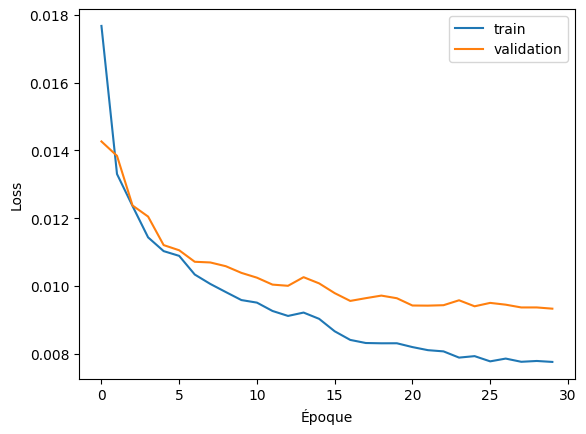

In [12]:
import os
MODEL_DIR = "/content/drive/MyDrive/speech-denoiser/models"
os.makedirs(MODEL_DIR, exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/gru_denoiser_best.keras",
                                    monitor="val_loss", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

history = model.fit(train_ds, steps_per_epoch=300, epochs=30,
                    validation_data=val_ds, callbacks=callbacks)

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Époque"); plt.ylabel("Loss"); plt.legend(); plt.show()

In [13]:
from tensorflow import keras
MODEL_DIR = "/content/drive/MyDrive/speech-denoiser/models"
!ls -lh {MODEL_DIR}

model = keras.models.load_model(f"{MODEL_DIR}/gru_denoiser_best.keras", compile=False)
model.summary()

total 11M
-rw------- 1 root root 11M Oct  1 16:45 gru_denoiser_best.keras


Model: "gru_denoiser"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ log_mag (InputLayer)            │ (None, None, 257)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, None, 257)      │           515 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 256)      │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, None, 256)      │       394,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, None, 256)      │       394,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mask (Dense)                    │ (None, None, 257)      │        66,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 922,116 (3.52 MB)

 Trainable params: 921,601 (3.52 MB)

 Non-trainable params: 515 (2.02 KB)

In [14]:
def enhance(x):
    S = stft(x.astype(np.float32))
    m = model(tf.math.log(tf.abs(S) + 1e-6)[None])[0]
    return istft(tf.cast(m, tf.complex64) * S).numpy()

for i in [0, 10, 100]:
    n = test_noisy[i].astype(np.float32) / 32767
    c = test_clean[i].astype(np.float32) / 32767
    e = enhance(n)
    print(f"Clip test {i} : bruité {snr_db(c, n):.1f} dB -> modèle {snr_db(c, e):.1f} dB")

i = 0
n = test_noisy[i].astype(np.float32) / 32767
print("Bruitée :"); display(Play(n, rate=SR))
print("Débruitée par ton modèle :"); display(Play(enhance(n), rate=SR))

Clip test 0 : bruité 15.5 dB -> modèle 23.8 dB
Clip test 10 : bruité 6.8 dB -> modèle 13.0 dB
Clip test 100 : bruité 15.4 dB -> modèle 19.8 dB
Bruitée :


Débruitée par ton modèle :


In [15]:
def enhance(x):
    S = stft(x.astype(np.float32))
    m = model(tf.math.log(tf.abs(S) + 1e-6)[None])[0]
    y = istft(tf.cast(m, tf.complex64) * S).numpy()
    return np.pad(y, (0, max(0, len(x) - len(y))))[:len(x)]  # même longueur que l'entrée

Clips les plus bruités : [(588, np.float32(-3.1)), (680, np.float32(-1.3)), (488, np.float32(-0.7)), (75, np.float32(-0.7)), (432, np.float32(-0.7))]
Clip 588 : bruité -3.1 dB -> modèle 14.5 dB
Bruitée :


Débruitée :


Ce que le modèle a retiré :


Propre (référence) :


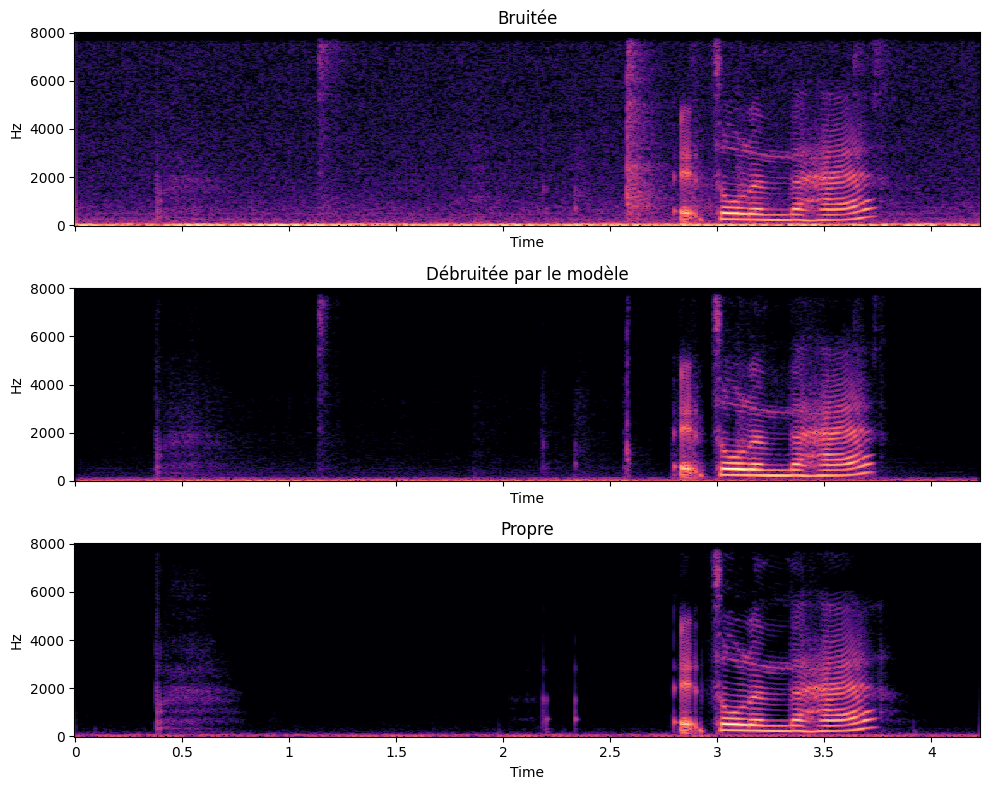

In [16]:
# 1) Trouver les 5 clips de test les plus bruités
snrs = [snr_db(c.astype(np.float32)/32767, n.astype(np.float32)/32767)
        for n, c in zip(test_noisy, test_clean)]
worst = np.argsort(snrs)[:5]
print("Clips les plus bruités :", [(int(i), round(snrs[i], 1)) for i in worst])

# 2) Écouter le pire
i = int(worst[0])
n = test_noisy[i].astype(np.float32) / 32767
c = test_clean[i].astype(np.float32) / 32767
e = enhance(n)
print(f"Clip {i} : bruité {snr_db(c, n):.1f} dB -> modèle {snr_db(c, e):.1f} dB")

print("Bruitée :");                 display(Play(n, rate=SR, normalize=False))
print("Débruitée :");               display(Play(e, rate=SR, normalize=False))
print("Ce que le modèle a retiré :"); display(Play(n - e, rate=SR, normalize=False))
print("Propre (référence) :");      display(Play(c, rate=SR, normalize=False))

# 3) Spectrogrammes côte à côte
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, x, title in zip(axes, [n, e, c], ["Bruitée", "Débruitée par le modèle", "Propre"]):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(x, n_fft=512, hop_length=128)), ref=np.max)
    librosa.display.specshow(S, sr=SR, hop_length=128, x_axis='time', y_axis='hz', ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.show()

In [17]:
import soundfile as sf, os
OUT = "/content/drive/MyDrive/speech-denoiser/examples"
os.makedirs(OUT, exist_ok=True)
fig.savefig(f"{OUT}/spectrogrammes_clip588.png", dpi=150, bbox_inches="tight")

for i in [588, 680, 0]:
    n = test_noisy[i].astype(np.float32) / 32767
    c = test_clean[i].astype(np.float32) / 32767
    sf.write(f"{OUT}/clip{i}_1_bruite.wav",   n, SR)
    sf.write(f"{OUT}/clip{i}_2_debruite.wav", enhance(n), SR)
    sf.write(f"{OUT}/clip{i}_3_propre.wav",   c, SR)
!ls {OUT}

clip0_1_bruite.wav    clip588_2_debruite.wav  clip680_3_propre.wav
clip0_2_debruite.wav  clip588_3_propre.wav    spectrogrammes_clip588.png
clip0_3_propre.wav    clip680_1_bruite.wav
clip588_1_bruite.wav  clip680_2_debruite.wav


In [18]:
!pip install -q pesq pystoi
from pesq import pesq
from pystoi import stoi
import pandas as pd

def pad_to(y, L):
    return np.pad(y, (0, max(0, L - len(y))))[:L]

rows = []
for i in tqdm(range(len(test_noisy))):
    n = test_noisy[i].astype(np.float32) / 32767
    c = test_clean[i].astype(np.float32) / 32767
    e = enhance(n)
    Sn, Sc = stft(n), stft(c)
    mk = tf.clip_by_value(tf.abs(Sc) / (tf.abs(Sn) + 1e-8), 0.0, 1.0)
    o = pad_to(istft(tf.cast(mk, tf.complex64) * Sn).numpy(), len(n))
    for name, x in [("Bruité", n), ("Modèle", e), ("Oracle", o)]:
        try:
            p = pesq(SR, c, x, "wb")
        except Exception:
            p = np.nan
        rows.append({"clip": i, "version": name, "SNR": snr_db(c, x),
                     "PESQ": p, "STOI": stoi(c, x, SR, extended=False)})

df = pd.DataFrame(rows)
summary = df.groupby("version")[["SNR", "PESQ", "STOI"]].mean().round(3).loc[["Bruité", "Modèle", "Oracle"]]
print(summary)
df.to_csv("/content/drive/MyDrive/speech-denoiser/results_test.csv", index=False)

  Preparing metadata (setup.py) ... done


  0%|          | 0/824 [00:00<?, ?it/s]

               SNR   PESQ   STOI
version                         
Bruité    8.450000  1.972  0.922
Modèle   17.431999  2.714  0.940
Oracle   19.763000  3.885  0.987


In [21]:
import time
T = 125  # trames par bloc = environ 1,02 s d'audio

# 1) Même architecture, version embarquée, puis copie des poids entraînés
def build_fixed(T):
    inp = keras.Input(shape=(T, F), batch_size=1, name="log_mag")
    x = layers.Normalization(axis=-1)(inp)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.GRU(256, return_sequences=True, use_cudnn=False, unroll=True)(x)
    x = layers.GRU(256, return_sequences=True, use_cudnn=False, unroll=True)(x)
    out = layers.Dense(F, activation="sigmoid", name="mask")(x)
    return keras.Model(inp, out, name="gru_denoiser_fixed")

fixed = build_fixed(T)
fixed.set_weights(model.get_weights())

fixed = build_fixed(T)
fixed.set_weights(model.get_weights())
[l for l in fixed.layers if isinstance(l, layers.Normalization)][0].finalize_state()

# Vérification : les deux versions doivent donner le même masque
xt = np.random.randn(1, T, F).astype(np.float32)
print("Écart max entre les deux versions :", float(np.abs(fixed(xt).numpy() - model(xt).numpy()).max()))

# 2) Export en SavedModel, puis conversion TFLite (un convertisseur neuf à chaque essai)
EXPORT = "/content/denoiser_savedmodel"
fixed.export(EXPORT)

def convert(quantize, select_ops=False):
    conv = tf.lite.TFLiteConverter.from_saved_model(EXPORT)
    if quantize:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]  # poids en int8
    if select_ops:
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]
        conv._experimental_lower_tensor_list_ops = False
    return conv.convert()

def safe_convert(quantize):
    try:
        return convert(quantize)
    except Exception as err:
        print("Conversion standard impossible :", str(err)[:500])
        return convert(quantize, select_ops=True)

tfl_f32, tfl_int8 = safe_convert(False), safe_convert(True)
for name, b in [("float32", tfl_f32), ("int8", tfl_int8)]:
    open(f"{MODEL_DIR}/denoiser_{name}.tflite", "wb").write(b)
    print(f"TFLite {name} : {len(b)/1e6:.2f} Mo")

Écart max entre les deux versions : 3.5762786865234375e-07
Saved artifact at '/content/denoiser_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 125, 257), dtype=tf.float32, name='log_mag')
Output Type:
  TensorSpec(shape=(None, 125, 257), dtype=tf.float32, name=None)
Captures:
  140034926565072: TensorSpec(shape=(1, 1, 257), dtype=tf.float32, name=None)
  140034926575248: TensorSpec(shape=(1, 1, 257), dtype=tf.float32, name=None)
  140034926572176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034926571984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034926566416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034926564496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034926563344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034926562576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034926565840: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [22]:
F_ = 257
x_blk = np.random.randn(1, T, F_).astype(np.float32)
block_dur = ((T - 1) * HOP + N_FFT) / SR  # durée d'audio couverte par un bloc

def bench_tflite(b, runs=50):
    it = tf.lite.Interpreter(model_content=b, num_threads=1)
    it.allocate_tensors()
    i_in, i_out = it.get_input_details()[0]["index"], it.get_output_details()[0]["index"]
    it.set_tensor(i_in, x_blk); it.invoke()  # échauffement
    t0 = time.perf_counter()
    for _ in range(runs):
        it.set_tensor(i_in, x_blk); it.invoke()
    return (time.perf_counter() - t0) / runs

def bench_keras(runs=20):
    model(x_blk)  # échauffement
    t0 = time.perf_counter()
    for _ in range(runs):
        model(x_blk)
    return (time.perf_counter() - t0) / runs

for name, dt in [("Keras", bench_keras()), ("TFLite float32", bench_tflite(tfl_f32)), ("TFLite int8", bench_tflite(tfl_int8))]:
    print(f"{name:15s} | {dt*1000:7.1f} ms par bloc de {block_dur:.2f} s | "
          f"{dt/T*1000:.3f} ms par trame | RTF = {dt/block_dur:.3f}")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Keras           |    21.0 ms par bloc de 1.02 s | 0.168 ms par trame | RTF = 0.021
TFLite float32  |    44.1 ms par bloc de 1.02 s | 0.353 ms par trame | RTF = 0.043
TFLite int8     |    23.5 ms par bloc de 1.02 s | 0.188 ms par trame | RTF = 0.023


In [23]:
def enhance_tflite(x, b):
    it = tf.lite.Interpreter(model_content=b); it.allocate_tensors()
    i_in, i_out = it.get_input_details()[0]["index"], it.get_output_details()[0]["index"]
    S = stft(x.astype(np.float32)); X = np.log(np.abs(S.numpy()) + 1e-6)
    nF = X.shape[0]; Xp = np.pad(X, ((0, (-nF) % T), (0, 0)))
    M = []
    for k in range(0, Xp.shape[0], T):
        it.set_tensor(i_in, Xp[None, k:k+T].astype(np.float32)); it.invoke()
        M.append(it.get_tensor(i_out)[0])
    M = np.concatenate(M)[:nF]
    return pad_to(istft(tf.cast(M, tf.complex64) * S).numpy(), len(x))

res = {"Keras": [], "TFLite float32": [], "TFLite int8": []}
for i in tqdm(range(100)):
    n = test_noisy[i].astype(np.float32) / 32767
    c = test_clean[i].astype(np.float32) / 32767
    for name, e in [("Keras", enhance(n)), ("TFLite float32", enhance_tflite(n, tfl_f32)),
                    ("TFLite int8", enhance_tflite(n, tfl_int8))]:
        res[name].append(pesq(SR, c, e, "wb"))
for name, v in res.items():
    print(f"{name:15s} PESQ moyen (100 clips) : {np.mean(v):.3f}")

  0%|          | 0/100 [00:00<?, ?it/s]

Keras           PESQ moyen (100 clips) : 2.777
TFLite float32  PESQ moyen (100 clips) : 2.665
TFLite int8     PESQ moyen (100 clips) : 2.664
